# 03 · Foundation Model

Chronos-Bolt (base) zero-shot: keine Trainingsdaten, keine Kovariaten, nur die letzten 2048 Stunden als Kontext. Berechnet auf MPS, vorab im Backtest.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from src.report import COLORS, MODELS, INK, MUTED, BLUES, DAYS
from src.backtest import RESULTS
from src.report import leaderboard, holiday_split
from IPython.display import Markdown

/Users/p.schmidt-petter/Desktop/dev/dev/pedestrian_traffic_forecast/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
fc = pd.read_parquet(RESULTS / 'forecasts.parquet')
fc['model'] = fc['model'].astype(str)
metrics = pd.read_parquet(RESULTS / 'metrics.parquet')
history = pd.read_parquet(RESULTS / 'history.parquet')
Markdown(leaderboard(metrics))

| Modell | MASE 24 h | MASE 7 d | sMAPE 24 h | sMAPE 7 d | Abdeckung 80 % (7 d) |
|---|---|---|---|---|---|
| Chronos-Bolt | 0.749 | 0.796 | 19.6 % | 21.5 % | 80 % |
| LightGBM | **0.711** | **0.769** | 16.6 % | 18.8 % | 69 % |
| Prophet | 1.098 | 1.019 | 23.3 % | 23.0 % | 84 % |
| MSTL-ETS | 1.233 | 1.303 | 23.0 % | 26.5 % | 96 % |
| SeasonalNaive | 1.016 | 1.012 | 24.5 % | 24.6 % | 87 % |

## Fehler über den Vorhersagehorizont

Chronos-Bolt sagt direkt 64 Schritte voraus, darüber hinaus rollt es autoregressiv auf dem eigenen Median weiter.

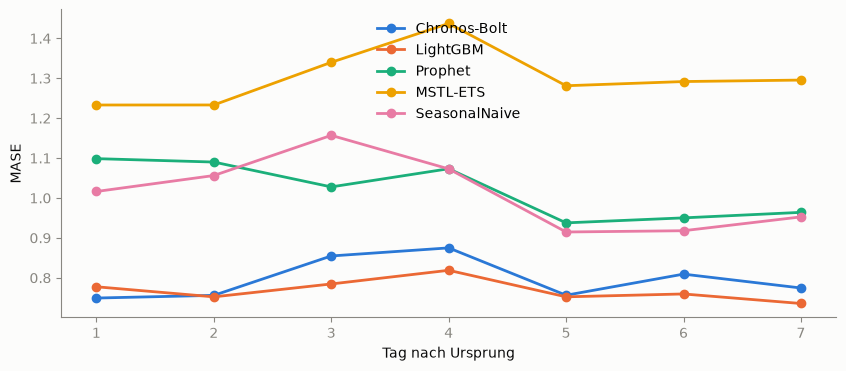

In [3]:
d = fc[(fc.horizon == 168) & ~fc.imputed].copy()
d['lead'] = (d.ds - d.origin) / pd.Timedelta(hours=1)
d['ase'] = (d.y - d.yhat).abs() / d.scale
curve = d.groupby(['model', (d.lead - 1) // 24 + 1]).ase.mean().unstack(0)
fig, ax = plt.subplots(figsize=(10, 4))
for m in MODELS:
    ax.plot(curve.index, curve[m], color=COLORS[m], marker='o', linewidth=2, label=m)
ax.set(xlabel='Tag nach Ursprung', ylabel='MASE')
ax.legend(frameon=False);

## Feiertage

In [4]:
Markdown(holiday_split(fc, history))

| Modell | MASE normale Tage | MASE Feiertage |
|---|---|---|
| Chronos-Bolt | 0.768 | 1.572 |
| LightGBM | 0.745 | 1.420 |
| Prophet | 0.994 | 1.747 |
| MSTL-ETS | 1.253 | 2.646 |
| SeasonalNaive | 0.979 | 1.938 |

## Pro Sensor und Woche: wer gewinnt?

Gewonnene Fenster (7 d):
Chronos-Bolt     130
LightGBM         164
Prophet           14
MSTL-ETS          40
SeasonalNaive     12
Name: count, dtype: int64


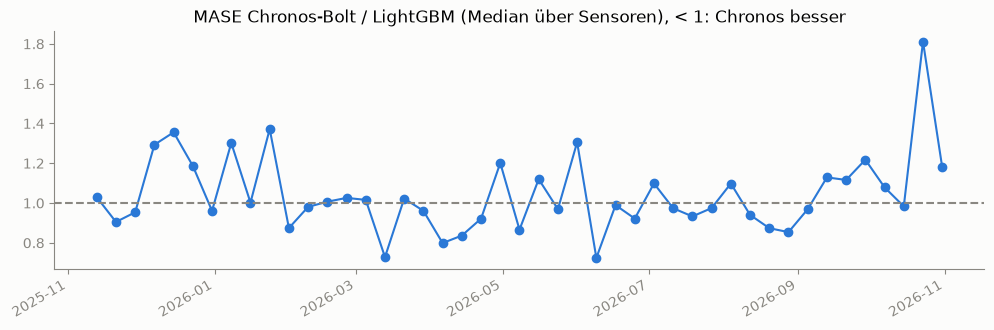

In [5]:
w = metrics[metrics.horizon == 168].pivot_table(index=['unique_id', 'origin'], columns='model', values='MASE')
wins = w.idxmin(axis=1).value_counts().reindex(MODELS).fillna(0).astype(int)
print('Gewonnene Fenster (7 d):')
print(wins)
rel = (w['Chronos-Bolt'] / w['LightGBM']).groupby(level='origin').median()
ax = rel.plot(figsize=(12, 3.5), color=COLORS['Chronos-Bolt'], marker='o')
ax.axhline(1, color=MUTED, linestyle='--')
ax.set(title='MASE Chronos-Bolt / LightGBM (Median über Sensoren), < 1: Chronos besser', xlabel='');

## Prognoseintervalle

In [6]:
metrics.groupby(['horizon', 'model']).Coverage80.mean().unstack(0).reindex(MODELS).round(1)

horizon,24,168
model,,
Chronos-Bolt,83.6,80.2
LightGBM,70.5,69.2
Prophet,83.3,83.7
MSTL-ETS,86.3,96.4
SeasonalNaive,87.7,87.2
